<a href="https://colab.research.google.com/github/pphantomfury/SemProject_MLEngine/blob/main/Dataset_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
michaelpawlus_fundraising_data_path = kagglehub.dataset_download('michaelpawlus/fundraising-data')

print('Data source import complete.')


Using Colab cache for faster access to the 'fundraising-data' dataset.
Data source import complete.


## Introduction
Greetings from the Kaggle bot! This is an automatically-generated kernel with starter code demonstrating how to read in the data and begin exploring. If you're inspired to dig deeper, click the blue "Fork Notebook" button at the top of this kernel to begin editing.

## Exploratory Analysis
To begin this exploratory analysis, first import libraries and define functions for plotting the data using `matplotlib`. Depending on the data, not all plots will be made. (Hey, I'm just a simple kerneling bot, not a Kaggle Competitions Grandmaster!)

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt # plotting
import numpy as np # linear algebra
import os # accessing directory structure
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


There are 4 csv files in the current version of the dataset:


In [ ]:
import os
print(os.listdir('/kaggle/input'))

['fundraising-data']


The next hidden code cells define functions for plotting data. Click on the "Code" button in the published kernel to reveal the hidden code.

In [ ]:
# Histogram of column data
def plotHistogram(df, nHistogramShown, nHistogramPerRow):
    nunique = df.nunique()
    df = df[[col for col in df if nunique[col] > 1 and nunique[col] < 50]] # For displaying purposes, pick columns that have between 1 and 50 unique values
    nRow, nCol = df.shape
    columnNames = list(df)
    nHistRow = (nCol + nHistogramPerRow - 1) / nHistogramPerRow
    plt.figure(num=None, figsize=(6*nHistogramPerRow, 8*nHistRow), dpi=80, facecolor='w', edgecolor='k')
    for i in range(min(nCol, nHistogramShown)):
        plt.subplot(nHistRow, nHistogramPerRow, i+1)
        df.iloc[:,i].hist()
        plt.ylabel('counts')
        plt.xticks(rotation=90)
        plt.title(f'{columnNames[i]} (column {i})')
    plt.tight_layout(pad=1.0, w_pad=1.0, h_pad=1.0)
    plt.show()


In [ ]:
# Correlation matrix
def plotCorrelationMatrix(df, graphWidth):
    filename = df.dataframeName
    df = df.dropna('columns') # drop columns with NaN
    df = df[[col for col in df if df[col].nunique() > 1]] # keep columns where there are more than 1 unique values
    if df.shape[1] < 2:
        print(f'No correlation plots shown: The number of non-NaN or constant columns ({df.shape[1]}) is less than 2')
        return
    corr = df.corr()
    plt.figure(num=None, figsize=(graphWidth, graphWidth), dpi=80, facecolor='w', edgecolor='k')
    corrMat = plt.matshow(corr, fignum = 1)
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.gca().xaxis.tick_bottom()
    plt.colorbar(corrMat)
    plt.title(f'Correlation Matrix for {filename}', fontsize=15)
    plt.show()


In [ ]:
# Scatter and density plots
def plotScatterMatrix(df, plotSize, textSize):
    df = df.select_dtypes(include =[np.number]) # keep only numerical columns
    # Remove rows and columns that would lead to df being singular
    df = df.dropna('columns')
    df = df[[col for col in df if df[col].nunique() > 1]] # keep columns where there are more than 1 unique values
    columnNames = list(df)
    if len(columnNames) > 10: # reduce the number of columns for matrix inversion of kernel density plots
        columnNames = columnNames[:10]
    df = df[columnNames]
    ax = pd.plotting.scatter_matrix(df, alpha=0.75, figsize=[plotSize, plotSize], diagonal='kde')
    corrs = df.corr().values
    for i, j in zip(*plt.np.triu_indices_from(ax, k = 1)):
        ax[i, j].annotate('Corr. coef = %.3f' % corrs[i, j], (0.8, 0.2), xycoords='axes fraction', ha='center', va='center', size=textSize)
    plt.suptitle('Scatter and Density Plot')
    plt.show()


Now you're ready to read in the data and use the plotting functions to visualize the data.

### Let's check 1st file: ../input/data_science_for_fundraising_contact_reports.csv

In [ ]:
nRowsRead = 1000 # specify 'None' if want to read whole file
df1 = pd.read_csv('/kaggle/input/fundraising-data/data_science_for_fundraising_contact_reports.csv', delimiter=',', nrows=nRowsRead)
df1.dataframeName = 'data_science_for_fundraising_contact_reports.csv'
nRow, nCol = df1.shape
print(f'There are {nRow} rows and {nCol} columns')

There are 196 rows and 7 columns


Let's take a quick look at what the data looks like:

In [ ]:
import pandas as pd
import os # Import os for path manipulation
import kagglehub # Import kagglehub to define the path

# Define michaelpawlus_fundraising_data_path if it's not available in the current scope
michaelpawlus_fundraising_data_path = kagglehub.dataset_download('michaelpawlus/fundraising-data')

nRowsRead = 1000 # specify 'None' if want to read whole file

# Construct the correct file path using the downloaded dataset path
file_name = 'data_science_for_fundraising_contact_reports.csv'
file_path = os.path.join(michaelpawlus_fundraising_data_path, file_name)

df1 = pd.read_csv(file_path, delimiter=',', nrows=nRowsRead)
df1.dataframeName = file_name
df1.head(5)

Using Colab cache for faster access to the 'fundraising-data' dataset.


,Staff Name,Method,Date,Summary,Substantive,Donor,Outcome
0,Ann Marie Levier,Email,12/1/17,Sent Dominic an email asking for an update if ...,Y,Dominic Richards,Positive
1,Ann Marie Levier,Email,12/1/17,"Emailed Dr. Jonathan Winters, who have ties to...",Y,William Bendrich,Positive
2,Ann Marie Levier,Letter,11/30/17,"Sent Belinda an upgrade brochure, appeal lette...",Y,Belinda Carlyle,Positive
3,Deborah Mettier,Phone,11/29/17,$50k to extend Kendrick Memorial Undergraduate...,Y,Donna Gilbert,Positive
4,Ann Marie Levier,Letter,11/27/17,Sent upgrade brochure asking Jeffrey and Julie...,Y,Jeffrey Jantz,Positive


Histogram of sampled columns:

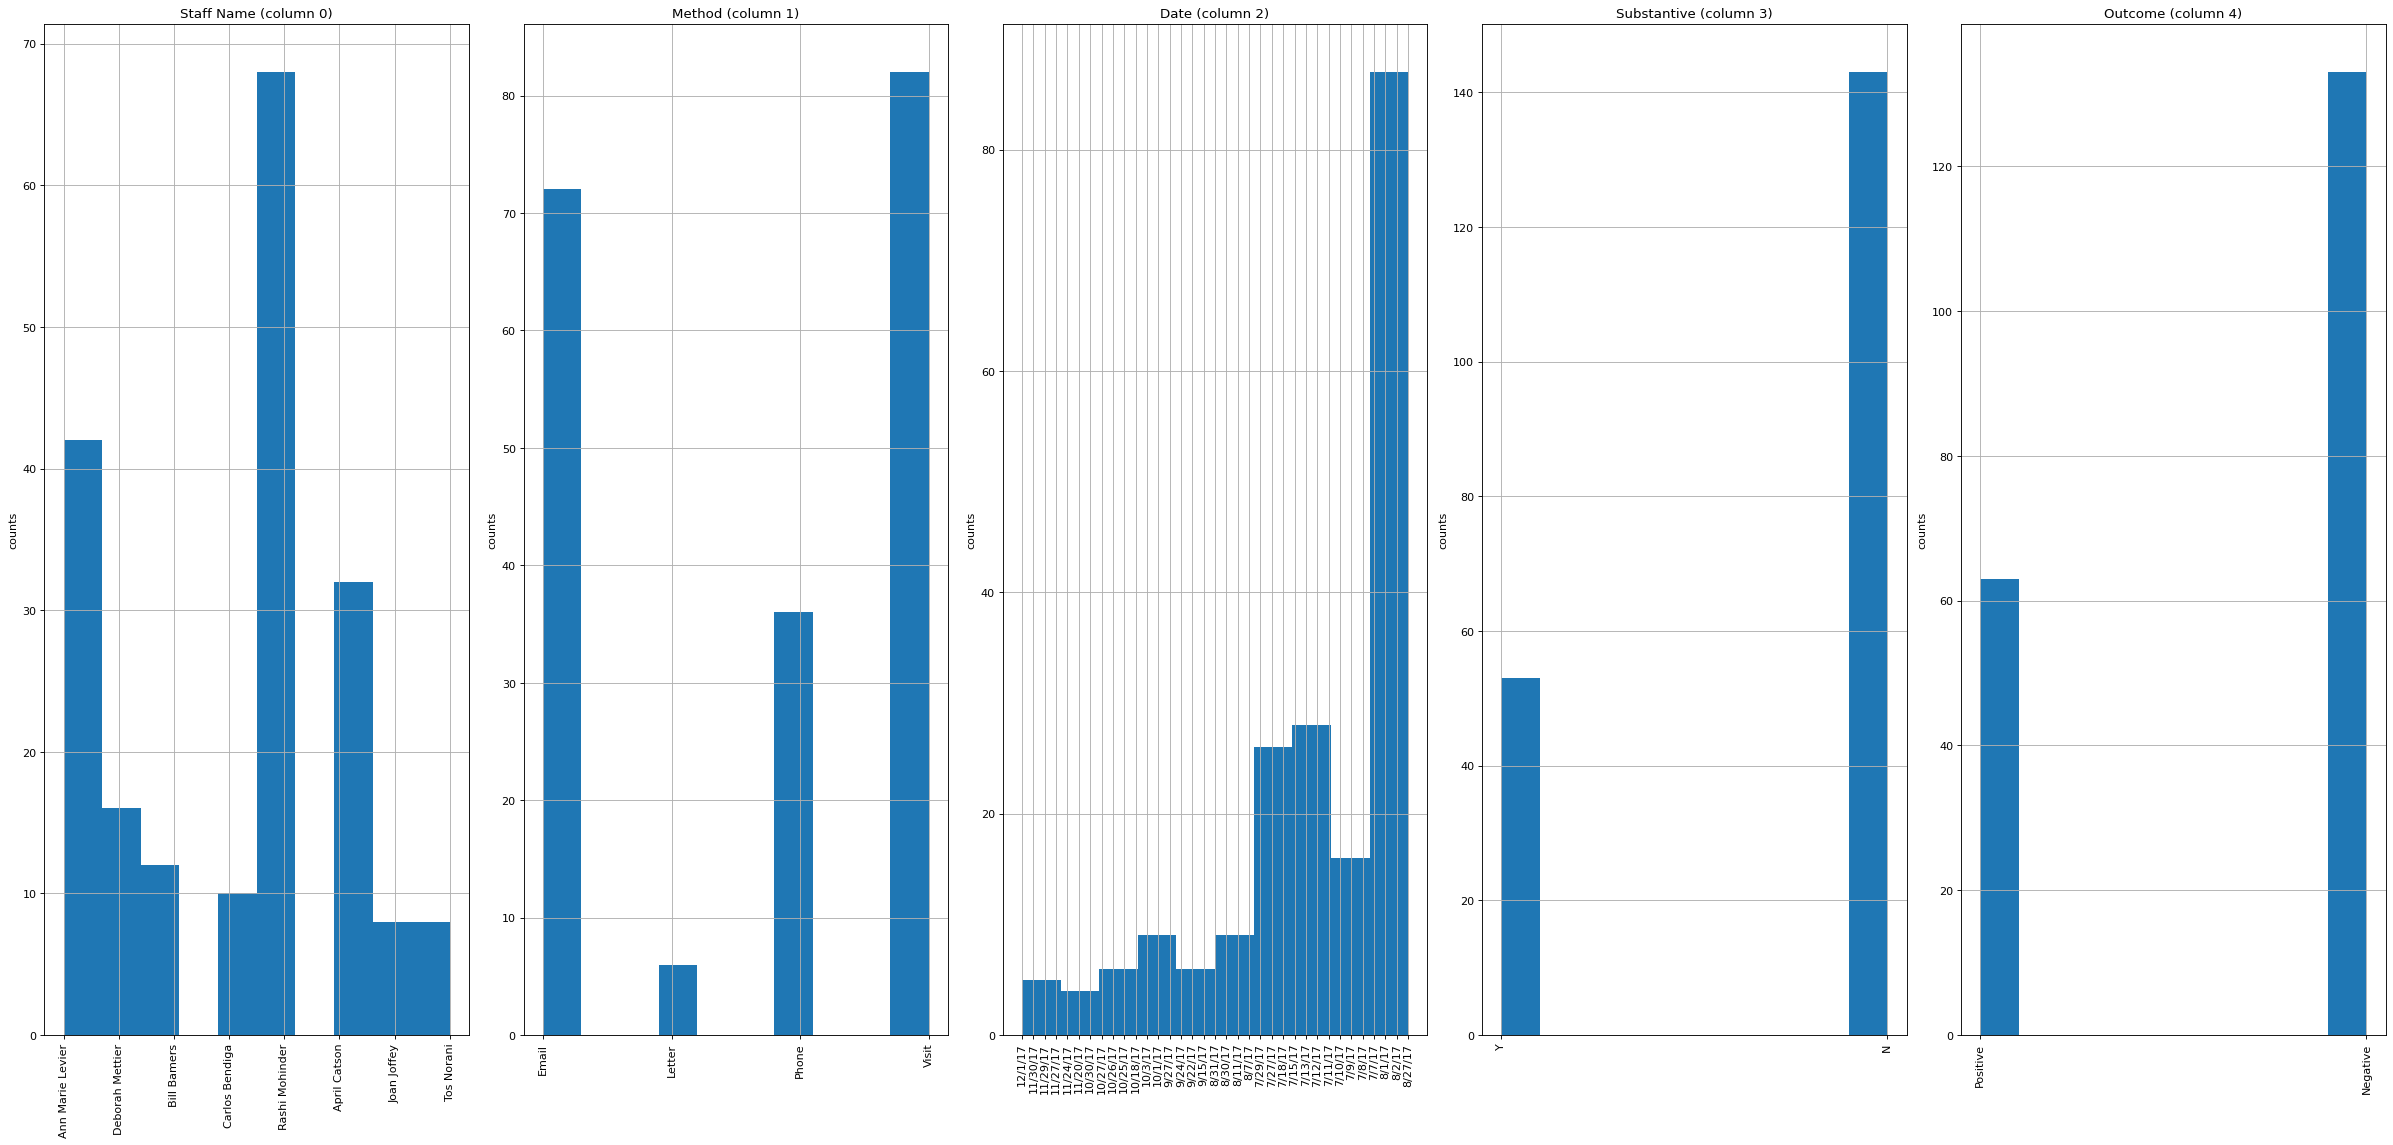

In [ ]:
plotHistogram(df1, 10, 5)

Correlation matrix for sampled columns:

In [ ]:
plotCorrelationMatrix(df1, 8)

In [ ]:
def plotHistogram(df, nHistogramShown, nHistogramPerRow):
    ...

### Let's check 2nd file: ../input/data_science_for_fundraising_donor_data.csv

In [ ]:
nRowsRead = 1000 # specify 'None' if want to read whole file
# data_science_for_fundraising_donor_data.csv has 34508 rows in reality, but we are only loading/previewing the first 1000 rows
df2 = pd.read_csv('/kaggle/input/fundraising-data/data_science_for_fundraising_donor_data.csv', delimiter=',', nrows=nRowsRead)
df2.dataframeName = 'data_science_for_fundraising_donor_data.csv'
nRow, nCol = df2.shape
print(f'There are {nRow} rows and {nCol} columns')

There are 1000 rows and 23 columns


Let's take a quick look at what the data looks like:

In [ ]:
df2.head(5)

,ID,ZIPCODE,AGE,MARITAL_STATUS,GENDER,MEMBERSHIP_IND,ALUMNUS_IND,PARENT_IND,HAS_INVOLVEMENT_IND,WEALTH_RATING,...,CON_YEARS,PrevFYGiving,PrevFY1Giving,PrevFY2Giving,PrevFY3Giving,PrevFY4Giving,CurrFYGiving,TotalGiving,DONOR_IND,BIRTH_DATE
0,1,23187.0,NaN,Married,Female,N,N,N,N,NaN,...,1,$0,$0,$0,$0,$0,$0,10.0,Y,NaN
1,2,77643.0,33.0,NaN,Female,N,Y,N,Y,NaN,...,0,$0,$0,$0,$0,$0,$0,2100.0,Y,1984-06-16
2,3,NaN,NaN,Married,Female,N,N,N,N,NaN,...,1,$0,$0,$0,$0,$0,$200,200.0,Y,NaN
3,4,47141.0,31.0,NaN,Female,N,Y,N,Y,NaN,...,0,$0,$0,$0,$0,$0,$0,0.0,N,1986-12-03
4,5,92555.0,68.0,NaN,Female,N,N,N,N,NaN,...,0,$0,$0,$0,$0,$0,$0,505.0,Y,1949-09-11


Histogram of sampled columns:

In [ ]:
plotHistogram(df2, 10, 5)

Correlation matrix for sampled columns (df2):

In [ ]:
plotCorrelationMatrix(df2, 8)

In [ ]:
import matplotlib.pyplot as plt

def plotHistogram(df, nHistogramShown, nHistogramPerRow):
    nunique = df.nunique()
    df = df[[col for col in df if nunique[col] > 1 and nunique[col] < 50]]
    nRow, nCol = df.shape
    columnNames = list(df)
    nHistRow = (nCol + nHistogramPerRow - 1) / nHistogramPerRow
    plt.figure(num=None, figsize=(6*nHistogramPerRow, 8*nHistRow), dpi=80, facecolor='w', edgecolor='k')
    for i in range(min(nCol, nHistogramShown)):
        plt.subplot(int(nHistRow), nHistogramPerRow, i+1)
        df.iloc[:, i].hist()
        plt.ylabel('counts')
        plt.xticks(rotation=90)
        plt.title(f'{columnNames[i]} (column {i})')
    plt.tight_layout(pad=1.0, w_pad=1.0, h_pad=1.0)
    plt.show()

Correlation matrix:

In [ ]:
def plotCorrelationMatrix(df, graphWidth):
    ...

Scatter and density plots:

In [ ]:
def plotScatterMatrix(df, plotSize, textSize):
    ...

### Let's check 3rd file: ../input/data_science_for_fundraising_sample_network.csv

In [ ]:
nRowsRead = 1000 # specify 'None' if want to read whole file
df3 = pd.read_csv('/kaggle/input/fundraising-data/data_science_for_fundraising_donor_data.csv', delimiter=',', nrows=nRowsRead)
df3.dataframeName = 'data_science_for_fundraising_donor_data.csv'
nRow, nCol = df3.shape
print(f'There are {nRow} rows and {nCol} columns')

There are 1000 rows and 23 columns


Let's take a quick look at what the data looks like:

In [ ]:
df3.head(5)

,ID,ZIPCODE,AGE,MARITAL_STATUS,GENDER,MEMBERSHIP_IND,ALUMNUS_IND,PARENT_IND,HAS_INVOLVEMENT_IND,WEALTH_RATING,...,CON_YEARS,PrevFYGiving,PrevFY1Giving,PrevFY2Giving,PrevFY3Giving,PrevFY4Giving,CurrFYGiving,TotalGiving,DONOR_IND,BIRTH_DATE
0,1,23187.0,NaN,Married,Female,N,N,N,N,NaN,...,1,$0,$0,$0,$0,$0,$0,10.0,Y,NaN
1,2,77643.0,33.0,NaN,Female,N,Y,N,Y,NaN,...,0,$0,$0,$0,$0,$0,$0,2100.0,Y,1984-06-16
2,3,NaN,NaN,Married,Female,N,N,N,N,NaN,...,1,$0,$0,$0,$0,$0,$200,200.0,Y,NaN
3,4,47141.0,31.0,NaN,Female,N,Y,N,Y,NaN,...,0,$0,$0,$0,$0,$0,$0,0.0,N,1986-12-03
4,5,92555.0,68.0,NaN,Female,N,N,N,N,NaN,...,0,$0,$0,$0,$0,$0,$0,505.0,Y,1949-09-11


Histogram of sampled columns:

In [ ]:
import matplotlib.pyplot as plt

def plotHistogram(df, nHistogramShown, nHistogramPerRow):
    nunique = df.nunique()
    df = df[[col for col in df if nunique[col] > 1 and nunique[col] < 50]]
    nRow, nCol = df.shape
    columnNames = list(df)
    nHistRow = (nCol + nHistogramPerRow - 1) / nHistogramPerRow
    plt.figure(num=None, figsize=(6*nHistogramPerRow, 8*nHistRow), dpi=80, facecolor='w', edgecolor='k')
    for i in range(min(nCol, nHistogramShown)):
        plt.subplot(int(nHistRow), nHistogramPerRow, i+1)
        df.iloc[:, i].hist()
        plt.ylabel('counts')
        plt.xticks(rotation=90)
        plt.title(f'{columnNames[i]} (column {i})')
    plt.tight_layout(pad=1.0, w_pad=1.0, h_pad=1.0)
    plt.show()

How many rows and columns are contained in the dataset? (3 marks)


In [ ]:
print(f"df1 (contact reports) has {df1.shape[0]} rows and {df1.shape[1]} columns.")
print(f"df2 (donor data) has {df2.shape[0]} rows and {df2.shape[1]} columns.")

df1 (contact reports) has 196 rows and 7 columns.
df2 (donor data) has 1000 rows and 23 columns.


What datatypes are contained in the dataset? (3 marks)

In [ ]:
print("df1 (contact reports) datatypes:")
print(df1.dtypes)
print()

file_name_df2 = 'data_science_for_fundraising_donor_data.csv'
file_path_df2 = os.path.join(michaelpawlus_fundraising_data_path, file_name_df2)
df2 = pd.read_csv(file_path_df2, delimiter=',', nrows=nRowsRead)
df2.dataframeName = file_name_df2

print("df2 (donor data) datatypes:")
print(df2.dtypes)

df1 (contact reports) datatypes:
Staff Name     object
Method         object
Date           object
Summary        object
Substantive    object
Donor          object
Outcome        object
dtype: object

df2 (donor data) datatypes:
ID                       int64
ZIPCODE                float64
AGE                    float64
MARITAL_STATUS          object
GENDER                  object
MEMBERSHIP_IND          object
ALUMNUS_IND             object
PARENT_IND              object
HAS_INVOLVEMENT_IND     object
WEALTH_RATING           object
DEGREE_LEVEL            object
PREF_ADDRESS_TYPE       object
EMAIL_PRESENT_IND       object
CON_YEARS                int64
PrevFYGiving            object
PrevFY1Giving           object
PrevFY2Giving           object
PrevFY3Giving           object
PrevFY4Giving           object
CurrFYGiving            object
TotalGiving            float64
DONOR_IND               object
BIRTH_DATE              object
dtype: object


Is the dataset complete? i.e. no missing values? (2 marks)

In [ ]:
print("df1 (contact reports) missing values:")
print(df1.isnull().sum())
print()
print("df2 (donor data) missing values:")
print(df2.isnull().sum())

df1 (contact reports) missing values:
Staff Name     0
Method         0
Date           0
Summary        0
Substantive    0
Donor          0
Outcome        0
dtype: int64

df2 (donor data) missing values:
ID                       0
ZIPCODE                 91
AGE                    600
MARITAL_STATUS         727
GENDER                  18
MEMBERSHIP_IND           0
ALUMNUS_IND              0
PARENT_IND               0
HAS_INVOLVEMENT_IND      0
WEALTH_RATING          924
DEGREE_LEVEL           784
PREF_ADDRESS_TYPE      106
EMAIL_PRESENT_IND        0
CON_YEARS                0
PrevFYGiving             0
PrevFY1Giving            0
PrevFY2Giving            0
PrevFY3Giving            0
PrevFY4Giving            0
CurrFYGiving             0
TotalGiving              0
DONOR_IND                0
BIRTH_DATE             600
dtype: int64


Slice out the first 15 rows and last 20 rows and merge them into a new
dataframe titled “df_sample”. Display this new dataframe. (4 marks)

In [ ]:
first_15_rows = df1.head(15)
last_20_rows = df1.tail(20)
df_sample = pd.concat([first_15_rows, last_20_rows])
print(df_sample)

           Staff Name  Method      Date  \
0    Ann Marie Levier   Email   12/1/17   
1    Ann Marie Levier   Email   12/1/17   
2    Ann Marie Levier  Letter  11/30/17   
3     Deborah Mettier   Phone  11/29/17   
4    Ann Marie Levier  Letter  11/27/17   
5    Ann Marie Levier  Letter  11/24/17   
6    Ann Marie Levier  Letter  11/24/17   
7         Bill Bamers   Visit  11/20/17   
8      Carlos Bendiga   Email  10/30/17   
9    Ann Marie Levier   Email  10/27/17   
10   Ann Marie Levier   Email  10/27/17   
11   Ann Marie Levier   Phone  10/27/17   
12   Ann Marie Levier   Email  10/26/17   
13   Ann Marie Levier   Email  10/25/17   
14     Rashi Mohinder   Phone  10/18/17   
176    Rashi Mohinder   Email   8/27/17   
177    Rashi Mohinder   Visit   8/27/17   
178    Rashi Mohinder   Visit   8/27/17   
179    Rashi Mohinder   Phone   8/27/17   
180    Rashi Mohinder   Email   8/27/17   
181    Rashi Mohinder   Visit   8/27/17   
182    Rashi Mohinder   Email   8/27/17   
183        

## Conclusion
This concludes your starter analysis! To go forward from here, click the blue "Fork Notebook" button at the top of this kernel. This will create a copy of the code and environment for you to edit. Delete, modify, and add code as you please. Happy Kaggling!